# A28 不知道哪种服务引导有效，怎样边试边选择？

你有三种服务引导话术，只有被采用的话术能观察是否成功。比较随机、贪心、ε-greedy与UCB，理解探索本身具有成本。

先修：基础课 Python、NumPy、实验评价

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


### 1. 反馈机制
真实成功率只给环境和评价器，策略仅收到被选动作的0/1结果。伪遗憾用真实率计算，因此只在此类已知机制模拟中可得。

In [2]:
import numpy as np
import pandas as pd
rates = np.array([0.4, 0.48, 0.58])
horizon = 600

def run_bandit(method, seed, steps=horizon):
    rng = np.random.default_rng(seed)
    counts = np.zeros(3, int)
    success = np.zeros(3)
    rewards = []
    regret = []
    for t in range(steps):
        average = np.divide(success, counts, out=np.zeros(3), where=counts > 0)
        if t < 3:
            action = t
        elif method == 'random':
            action = int(rng.integers(3))
        elif method == 'epsilon' and rng.random() < 0.1:
            action = int(rng.integers(3))
        elif method == 'ucb':
            action = int(np.argmax(average + np.sqrt(2 * np.log(t + 1) / counts)))
        else:
            action = int(np.argmax(average))
        reward = int(rng.random() < rates[action])
        counts[action] += 1
        success[action] += reward
        rewards.append(reward)
        regret.append(float(rates.max() - rates[action]))
    return (np.cumsum(rewards), np.cumsum(regret), counts)

### 2. 单次轨迹看直觉
先观察一个种子。UCB把估计均值与不确定性奖励相加；没有充分尝试的动作会得到更高探索奖励。

In [3]:
methods = ['random', 'greedy', 'epsilon', 'ucb']
for method in methods:
    reward, regret, counts = run_bandit(method, 28)
    assert counts.sum() == horizon and np.all(np.diff(regret) >= -1e-10)
    plt.plot(regret, label=method)
plt.xlabel('决策轮次')
plt.ylabel('累计伪遗憾')
plt.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / 'one_run.png')
plt.close()

### 3. 多次独立重复
重复100条轨迹，报告累计成功和伪遗憾的均值及分布。比较相同轮数；不预设UCB在每个短期问题都优于ε-greedy。

In [4]:
rows = []
for method in methods:
    for seed in range(100):
        reward, regret, counts = run_bandit(method, seed + 2800)
        rows.append({'method': method, 'seed': seed, 'successes': int(reward[-1]), 'regret': float(regret[-1]), 'best_arm_selections': int(counts[2])})
results = pd.DataFrame(rows)
summary = results.groupby('method').agg(successes=('successes', 'mean'), regret=('regret', 'mean'), regret_std=('regret', 'std'))
results.to_csv(OUT_DIR / 'trials.csv', index=False)
summary.regret.plot.bar()
plt.ylabel('600轮平均伪遗憾')
plt.tight_layout()
plt.savefig(OUT_DIR / 'repeat.png')
plt.close()

### 4. 区分短期目标与长期学习
这里假设成功率不随时间变化且每次结果独立。真实话术可能影响后续顾客构成或产生延迟反馈，届时该模型不再直接适用。

In [5]:
metrics = {'true_rates': rates.tolist(), 'horizon': horizon, 'runs_per_method': 100, 'summary': summary.reset_index().to_dict('records')}
recommendation = '根据 trials.csv 选择与时间预算和探索代价相符的策略。本例动作不改变后续状态，使用老虎机即可；若行动影响未来库存或用户状态，需重新建立序贯模型。'

### 保存可核验的证据
把指标写入 JSON，并用本次输出形成有条件的建议。json.dumps 把字典变成文本；不会替你判断方案是否适合现实。

In [6]:
import json
(OUT_DIR / 'metrics.json').write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8')
(OUT_DIR / '决策建议.md').write_text('# 本次计算的决策建议\n\n' + recommendation + '\n\n## 实际指标\n```json\n' + json.dumps(metrics, ensure_ascii=False, indent=2) + '\n```\n\n这些结论只适用于本例显式假设；目标权重和风险偏好由人决定。', encoding='utf-8')
print(metrics)

{'true_rates': [0.4, 0.48, 0.58], 'horizon': 600, 'runs_per_method': 100, 'summary': [{'method': 'epsilon', 'successes': 325.61, 'regret': 22.605800000000098, 'regret_std': 23.887590674708807}, {'method': 'greedy', 'successes': 297.47, 'regret': 50.89080000000064, 'regret_std': 44.79942193169682}, {'method': 'random', 'successes': 293.72, 'regret': 55.91900000000013, 'regret_std': 1.8138666216709887}, {'method': 'ucb', 'successes': 316.07, 'regret': 32.48180000000008, 'regret_std': 6.310476839304173}]}


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

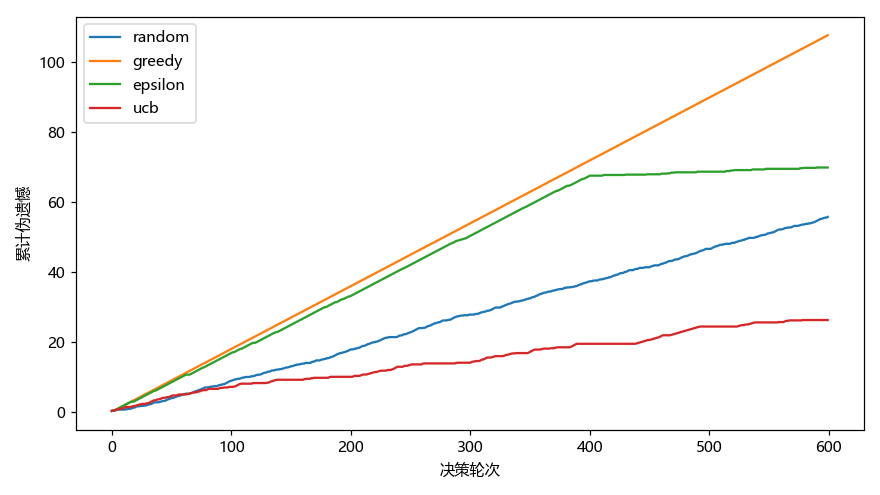

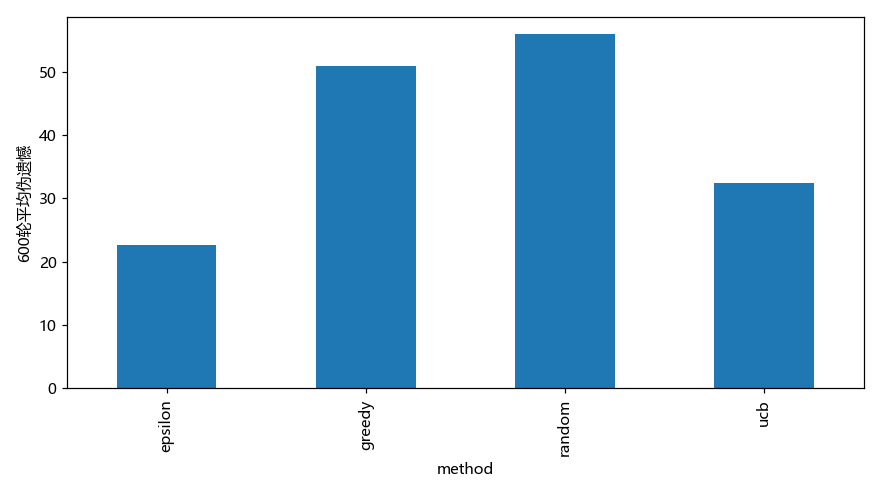

In [7]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
策略不能读取未选动作的实际反馈。模拟中计算遗憾所用真实概率不应传给策略。固定成功率只是教学假设。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。